In [140]:
import pandas as pd

df = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")

print(df.shape)
print(df["NObeyesdad"].value_counts())

(2111, 17)
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64


In [141]:
# Menampilkan 5 data teratas
df.head()

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [142]:
# Menampilkan jumlah baris dan kolom, serta nama kolom
print("Jumlah baris dan kolom:", df.shape)
print("Nama kolom:", df.columns.tolist())
df.info()

Jumlah baris dan kolom: (2111, 17)
Nama kolom: ['Age', 'Gender', 'Height', 'Weight', 'CALC', 'FAVC', 'FCVC', 'NCP', 'SCC', 'SMOKE', 'CH2O', 'family_history_with_overweight', 'FAF', 'TUE', 'CAEC', 'MTRANS', 'NObeyesdad']
<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   str    
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   str    
 9   SMOKE   

In [143]:
target = "NObeyesdad"
fitur = [k for k in df.columns if k != target]

print("Target :", target)
print("Fitur  :", fitur)

Target : NObeyesdad
Fitur  : ['Age', 'Gender', 'Height', 'Weight', 'CALC', 'FAVC', 'FCVC', 'NCP', 'SCC', 'SMOKE', 'CH2O', 'family_history_with_overweight', 'FAF', 'TUE', 'CAEC', 'MTRANS']


In [144]:
# Statistik deskriptif kolom numerik
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.312600,6.345968,14.00,19.947192,22.777890,26.000000,61.00
Height,2111.0,1.701677,0.093305,1.45,1.630000,1.700499,1.768464,1.98
Weight,2111.0,86.586058,26.191172,39.00,65.473343,83.000000,107.430682,173.00
FCVC,2111.0,2.419043,0.533927,1.00,2.000000,2.385502,3.000000,3.00
NCP,2111.0,2.685628,0.778039,1.00,2.658738,3.000000,3.000000,4.00
CH2O,2111.0,2.008011,0.612953,1.00,1.584812,2.000000,2.477420,3.00
FAF,2111.0,1.010298,0.850592,0.00,0.124505,1.000000,1.666678,3.00
TUE,2111.0,0.657866,0.608927,0.00,0.000000,0.625350,1.000000,2.00


In [145]:
# Distribusi target: jumlah data pada tiap kategori
print(df[target].value_counts())

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64


In [146]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [147]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(
    by='Missing Values',
    ascending=False
)

# Menampilkan kolom yang memiliki missing values
missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Percentage


In [148]:
duplicates = df.duplicated()
print("Jumlah baris duplikat:", duplicates.sum())

# Menampilkan semua baris yang kembar (termasuk aslinya) agar bisa dibandingkan
df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head(10)

Jumlah baris duplikat: 24


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
295,16.0,Female,1.66,58.0,no,no,2.0,1.0,no,no,1.0,no,0.0,1.0,Sometimes,Walking,Normal_Weight
309,16.0,Female,1.66,58.0,no,no,2.0,1.0,no,no,1.0,no,0.0,1.0,Sometimes,Walking,Normal_Weight
282,18.0,Female,1.62,55.0,no,yes,2.0,3.0,no,no,1.0,yes,1.0,1.0,Frequently,Public_Transportation,Normal_Weight
460,18.0,Female,1.62,55.0,no,yes,2.0,3.0,no,no,1.0,yes,1.0,1.0,Frequently,Public_Transportation,Normal_Weight
443,18.0,Male,1.72,53.0,Sometimes,yes,2.0,3.0,no,no,2.0,yes,0.0,2.0,Sometimes,Public_Transportation,Insufficient_Weight
496,18.0,Male,1.72,53.0,Sometimes,yes,2.0,3.0,no,no,2.0,yes,0.0,2.0,Sometimes,Public_Transportation,Insufficient_Weight
97,21.0,Female,1.52,42.0,Sometimes,no,3.0,1.0,no,no,1.0,no,0.0,0.0,Frequently,Public_Transportation,Insufficient_Weight
98,21.0,Female,1.52,42.0,Sometimes,no,3.0,1.0,no,no,1.0,no,0.0,0.0,Frequently,Public_Transportation,Insufficient_Weight
523,21.0,Female,1.52,42.0,Sometimes,yes,3.0,1.0,no,no,1.0,no,0.0,0.0,Frequently,Public_Transportation,Insufficient_Weight
527,21.0,Female,1.52,42.0,Sometimes,yes,3.0,1.0,no,no,1.0,no,0.0,0.0,Frequently,Public_Transportation,Insufficient_Weight


In [149]:
df_clean = df.drop_duplicates()
print(df_clean.shape)

(2087, 17)


In [150]:
df_clean.describe().T[["min", "25%", "50%", "75%", "max"]]

,min,25%,50%,75%,max
Age,14.00,19.915937,22.847618,26.000000,61.00
Height,1.45,1.630178,1.701584,1.769491,1.98
Weight,39.00,66.000000,83.101100,108.015907,173.00
FCVC,1.00,2.000000,2.396265,3.000000,3.00
NCP,1.00,2.697467,3.000000,3.000000,4.00
CH2O,1.00,1.590922,2.000000,2.466193,3.00
FAF,0.00,0.124505,1.000000,1.678102,3.00
TUE,0.00,0.000000,0.630866,1.000000,2.00


In [151]:
# Memeriksa kolom skala survei terhadap rentang yang seharusnya
rentang_skala = {"FCVC": (1, 3), "NCP": (1, 4), "CH2O": (1, 3), "FAF": (0, 3), "TUE": (0, 2)}

for k, (bawah, atas) in rentang_skala.items():
    di_luar = ((df_clean[k] < bawah) | (df_clean[k] > atas)).sum()
    print(k, "-> jumlah nilai di luar rentang", (bawah, atas), ":", di_luar)

FCVC -> jumlah nilai di luar rentang (1, 3) : 0
NCP -> jumlah nilai di luar rentang (1, 4) : 0
CH2O -> jumlah nilai di luar rentang (1, 3) : 0
FAF -> jumlah nilai di luar rentang (0, 3) : 0
TUE -> jumlah nilai di luar rentang (0, 2) : 0


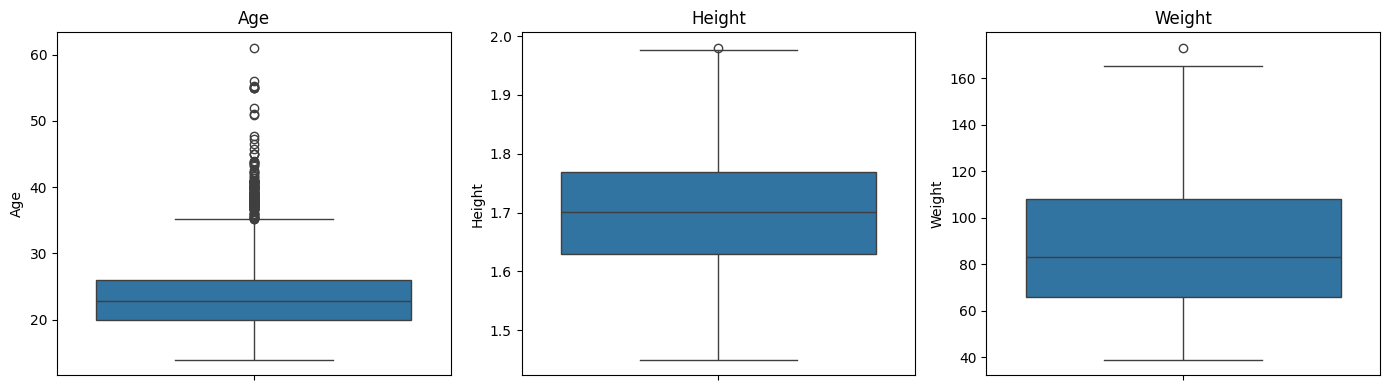

Age : 167
Height : 1
Weight : 1


In [152]:
import matplotlib.pyplot as plt
import seaborn as sns
kolom = ["Age", "Height", "Weight"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, k in zip(axes, kolom):
    sns.boxplot(data=df_clean, y=k, ax=ax)
    ax.set_title(k)

plt.tight_layout()
plt.show()

for k in kolom:
    q1 = df_clean[k].quantile(0.25)
    q3 = df_clean[k].quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    jumlah = ((df_clean[k] < batas_bawah) | (df_clean[k] > batas_atas)).sum()
    print(k, ":", jumlah)

In [153]:
# Memeriksa isi unik pada kolom teks (mencari tulisan ganda, spasi, atau salah ketik)
kolom_teks = df_clean.select_dtypes(exclude="number").columns

for k in kolom_teks:
    print(k, "->", df_clean[k].unique())

Gender -> <StringArray>
['Female', 'Male']
Length: 2, dtype: str
CALC -> <StringArray>
['no', 'Sometimes', 'Frequently', 'Always']
Length: 4, dtype: str
FAVC -> <StringArray>
['no', 'yes']
Length: 2, dtype: str
SCC -> <StringArray>
['no', 'yes']
Length: 2, dtype: str
SMOKE -> <StringArray>
['no', 'yes']
Length: 2, dtype: str
family_history_with_overweight -> <StringArray>
['yes', 'no']
Length: 2, dtype: str
CAEC -> <StringArray>
['Sometimes', 'Frequently', 'Always', 'no']
Length: 4, dtype: str
MTRANS -> <StringArray>
['Public_Transportation', 'Walking', 'Automobile', 'Motorbike', 'Bike']
Length: 5, dtype: str
NObeyesdad -> <StringArray>
[      'Normal_Weight',  'Overweight_Level_I', 'Overweight_Level_II',
      'Obesity_Type_I', 'Insufficient_Weight',     'Obesity_Type_II',
    'Obesity_Type_III']
Length: 7, dtype: str


In [154]:
# Menghitung jumlah nilai desimal pada kolom skala survei
kolom_skala = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]

for k in kolom_skala:
    jumlah = (df_clean[k] != df_clean[k].round()).sum()
    print(k, "-> nilai desimal:", jumlah, "dari", len(df_clean))

FCVC -> nilai desimal: 826 dari 2087
NCP -> nilai desimal: 640 dari 2087
CH2O -> nilai desimal: 1290 dari 2087
FAF -> nilai desimal: 1208 dari 2087
TUE -> nilai desimal: 1153 dari 2087


In [155]:
df_bulat = df_clean.copy()

for k in kolom_skala:
    df_bulat[k] = df_bulat[k].round().astype(int)

print(df_bulat.shape)
print(df_bulat[kolom_skala].nunique())

(2087, 17)
FCVC    3
NCP     4
CH2O    3
FAF     4
TUE     3
dtype: int64


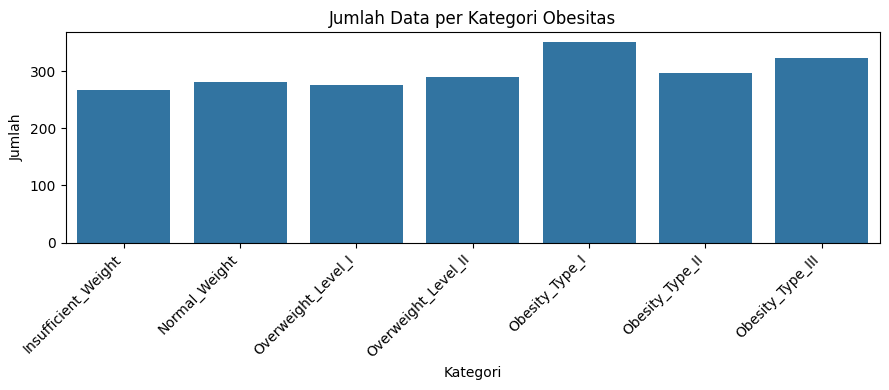

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64


In [156]:
import matplotlib.pyplot as plt
import seaborn as sns

urutan = ["Insufficient_Weight", "Normal_Weight",
          "Overweight_Level_I", "Overweight_Level_II",
          "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]

plt.figure(figsize=(9, 4))
sns.countplot(data=df_bulat, x="NObeyesdad", order=urutan)
plt.xticks(rotation=45, ha="right")
plt.title("Jumlah Data per Kategori Obesitas")
plt.xlabel("Kategori")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()
print(df_bulat["NObeyesdad"].value_counts())

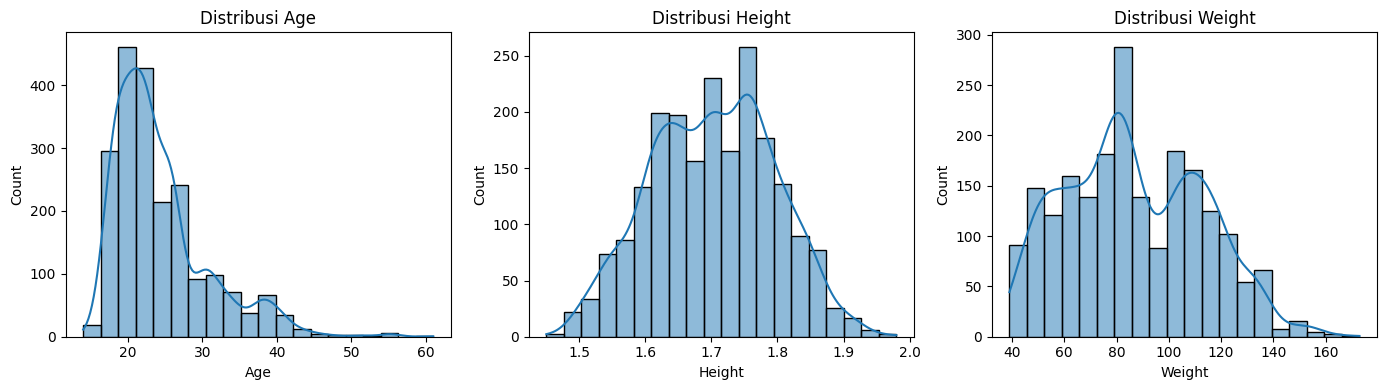

In [157]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, k in zip(axes, ["Age", "Height", "Weight"]):
    sns.histplot(data=df_bulat, x=k, bins=20, kde=True, ax=ax)
    ax.set_title(f"Distribusi {k}")

plt.tight_layout()
plt.show()

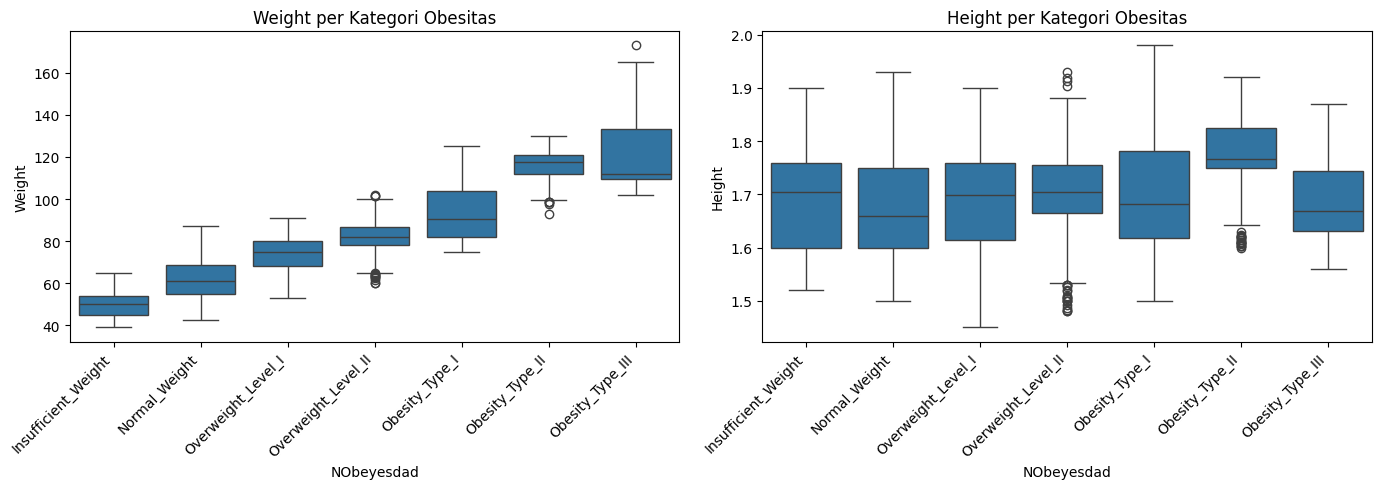

In [158]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, k in zip(axes, ["Weight", "Height"]):
    sns.boxplot(data=df_bulat, x="NObeyesdad", y=k, order=urutan, ax=ax)
    ax.set_title(f"{k} per Kategori Obesitas")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

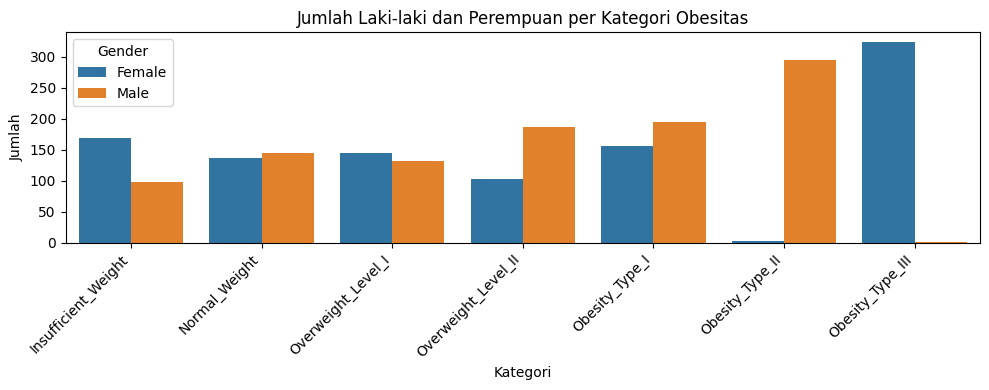

Gender,Female,Male
NObeyesdad,,
Insufficient_Weight,169,98
Normal_Weight,137,145
Overweight_Level_I,145,131
Overweight_Level_II,103,187
Obesity_Type_I,156,195
Obesity_Type_II,2,295
Obesity_Type_III,323,1


In [159]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df_bulat, x="NObeyesdad", hue="Gender", order=urutan)
plt.xticks(rotation=45, ha="right")
plt.title("Jumlah Laki-laki dan Perempuan per Kategori Obesitas")
plt.xlabel("Kategori")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()

# Angka pastinya
pd.crosstab(df_bulat["NObeyesdad"], df_bulat["Gender"]).reindex(urutan) 

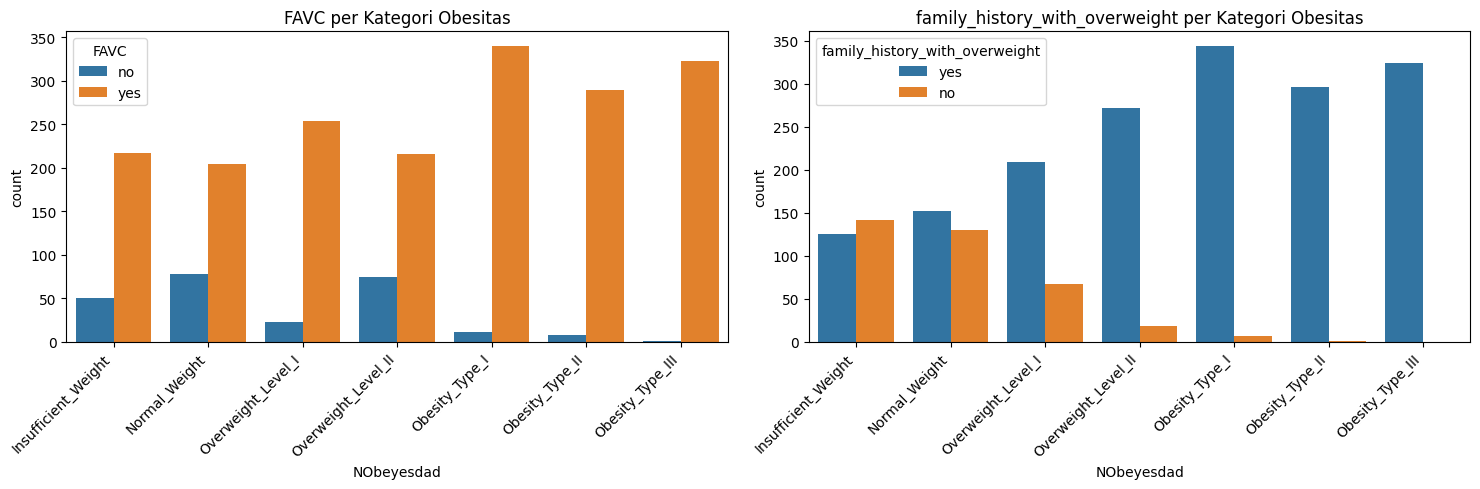

In [160]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, k in zip(axes, ["FAVC", "family_history_with_overweight"]):
    sns.countplot(data=df_bulat, x="NObeyesdad", hue=k, order=urutan, ax=ax)
    ax.set_title(f"{k} per Kategori Obesitas")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

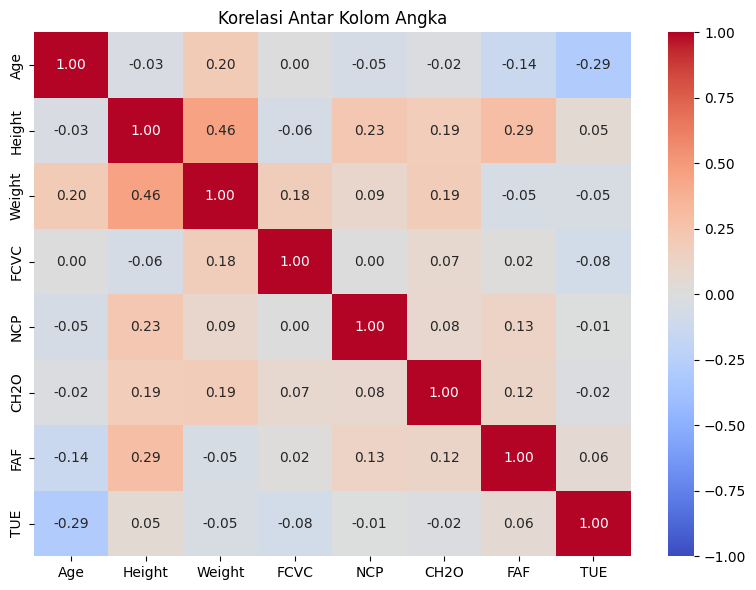

In [161]:
kolom_angka = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]

plt.figure(figsize=(8, 6))
sns.heatmap(df_bulat[kolom_angka].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi Antar Kolom Angka")
plt.tight_layout()
plt.show()

In [162]:
df_bulat.groupby(pd.cut(df_bulat["Age"], [13, 20, 25, 30, 40, 70]))["TUE"].mean()

Age
(13, 20]    0.878007
(20, 25]    0.756225
(25, 30]    0.471503
(30, 40]    0.411371
(40, 70]    0.087719
Name: TUE, dtype: float64

In [163]:
X = df_bulat.drop(columns="NObeyesdad")
y = df_bulat["NObeyesdad"]

print(X.shape)
print(y.shape)

(2087, 16)
(2087,)


In [164]:
# Salinan X supaya X asli (masih teks) tetap tersimpan
X_enc = X.copy()

# a) Kolom dua pilihan -> 0 dan 1
X_enc["Gender"] = X_enc["Gender"].map({"Female": 0, "Male": 1})

kolom_yesno = ["FAVC", "SCC", "SMOKE", "family_history_with_overweight"]
for k in kolom_yesno:
    X_enc[k] = X_enc[k].map({"no": 0, "yes": 1})

# b) Kolom bertingkat -> angka berurutan
tingkat = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
for k in ["CALC", "CAEC"]:
    X_enc[k] = X_enc[k].map(tingkat)

# c) Kolom tanpa urutan -> One-Hot Encoding
X_enc = pd.get_dummies(X_enc, columns=["MTRANS"], dtype=int)

print(X_enc.shape)
X_enc.head()

(2087, 20)


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,21.0,0,1.62,64.0,0,0,2,3,0,0,2,1,0,1,1,0,0,0,1,0
1,21.0,0,1.52,56.0,1,0,3,3,1,1,3,1,3,0,1,0,0,0,1,0
2,23.0,1,1.80,77.0,2,0,2,3,0,0,2,1,2,1,1,0,0,0,1,0
3,27.0,1,1.80,87.0,2,0,3,3,0,0,2,0,2,0,1,0,0,0,0,1
4,22.0,1,1.78,89.8,1,0,2,1,0,0,2,0,0,0,1,0,0,0,1,0


In [165]:
print(X_enc[["CALC", "CAEC"]].head())
print(X_enc[["CALC", "CAEC"]].isna().sum())
print("Total NaN:", X_enc.isna().sum().sum())

   CALC  CAEC
0     0     1
1     1     1
2     2     1
3     2     1
4     1     1
CALC    0
CAEC    0
dtype: int64
Total NaN: 0


In [166]:
# Pemeriksaan: tidak boleh ada nilai kosong akibat encoding, dan tidak boleh ada kolom teks tersisa
print("Total nilai kosong:", X_enc.isnull().sum().sum())
print("Kolom teks tersisa:", X_enc.select_dtypes(exclude="number").columns.tolist())

# Pemeriksaan One-Hot: tiap orang harus tepat satu kolom MTRANS bernilai 1
kolom_mtrans = [k for k in X_enc.columns if k.startswith("MTRANS_")]
print("Jumlah nilai 1 per baris pada kolom MTRANS:", X_enc[kolom_mtrans].sum(axis=1).unique())

Total nilai kosong: 0
Kolom teks tersisa: []
Jumlah nilai 1 per baris pada kolom MTRANS: [1]


In [167]:
kamus_target = {
    "Insufficient_Weight": 0,
    "Normal_Weight": 1,
    "Overweight_Level_I": 2,
    "Overweight_Level_II": 3,
    "Obesity_Type_I": 4,
    "Obesity_Type_II": 5,
    "Obesity_Type_III": 6,
}

y_enc = y.map(kamus_target)

print(y_enc.head())
print(y_enc.isnull().sum())
print(y_enc.value_counts().sort_index())

0    1
1    1
2    1
3    2
4    3
Name: NObeyesdad, dtype: int64
0
NObeyesdad
0    267
1    282
2    276
3    290
4    351
5    297
6    324
Name: count, dtype: int64


In [168]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y_enc, test_size=0.2, random_state=42, stratify=y_enc
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(1669, 20) (418, 20)
(1669,) (418,)


In [169]:
from sklearn.preprocessing import StandardScaler

kolom_scale = ["Age", "Height", "Weight"]
scaler = StandardScaler()

X_train_s = X_train.copy()
X_test_s = X_test.copy()

X_train_s[kolom_scale] = scaler.fit_transform(X_train[kolom_scale])
X_test_s[kolom_scale] = scaler.transform(X_test[kolom_scale])

print(X_train_s[kolom_scale].describe().T[["mean", "std"]].round(2))
print(X_test_s[kolom_scale].describe().T[["mean", "std"]].round(2))

        mean  std
Age      0.0  1.0
Height  -0.0  1.0
Weight  -0.0  1.0
        mean   std
Age    -0.05  0.99
Height  0.18  1.01
Weight  0.07  1.03


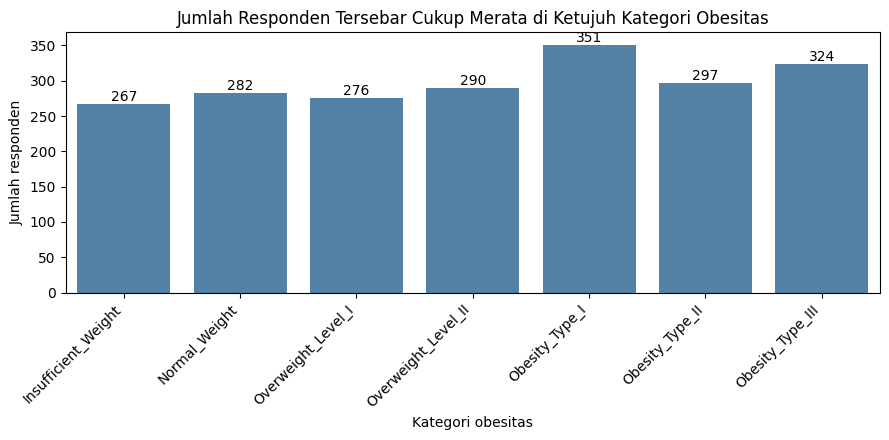

In [170]:
plt.figure(figsize=(9, 4.5))
ax = sns.countplot(data=df_bulat, x="NObeyesdad", order=urutan, color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Jumlah Responden Tersebar Cukup Merata di Ketujuh Kategori Obesitas")
plt.xlabel("Kategori obesitas")
plt.ylabel("Jumlah responden")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

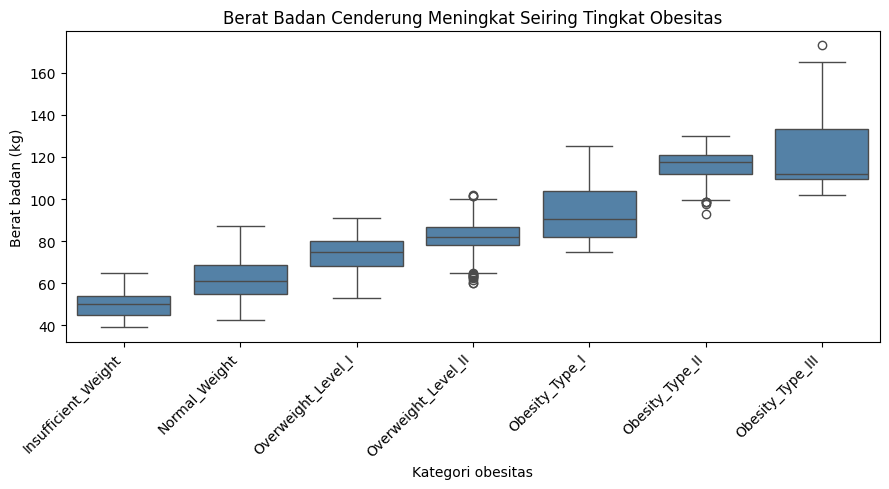

In [171]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_bulat, x="NObeyesdad", y="Weight", order=urutan, color="steelblue")
plt.title("Berat Badan Cenderung Meningkat Seiring Tingkat Obesitas")
plt.xlabel("Kategori obesitas")
plt.ylabel("Berat badan (kg)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

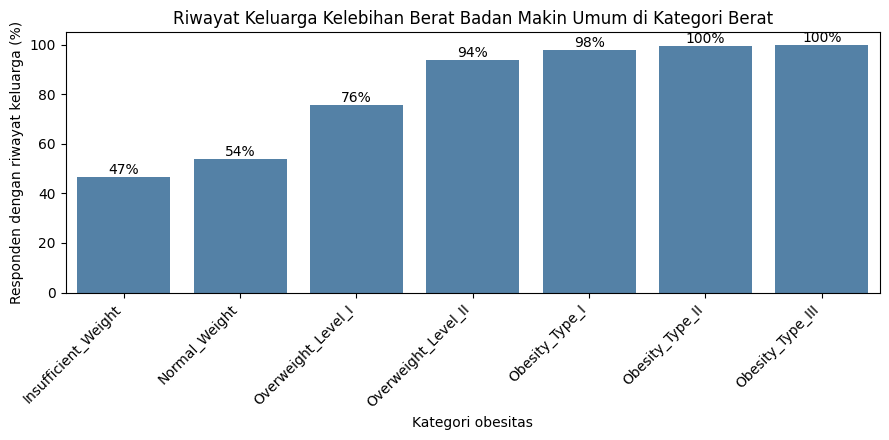

In [172]:
prop = (df_bulat["family_history_with_overweight"].eq("yes")
        .groupby(df_bulat["NObeyesdad"]).mean().reindex(urutan) * 100)

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(x=prop.index, y=prop.values, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.0f%%")
plt.title("Riwayat Keluarga Kelebihan Berat Badan Makin Umum di Kategori Berat")
plt.xlabel("Kategori obesitas")
plt.ylabel("Responden dengan riwayat keluarga (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

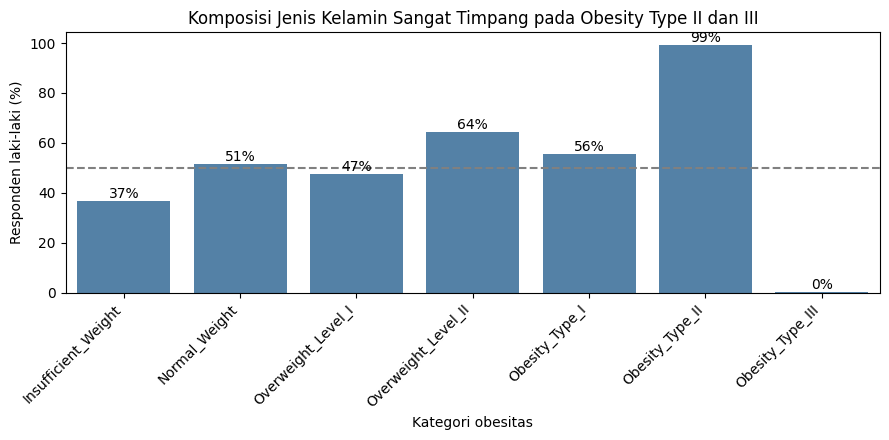

In [173]:
prop_l = (df_bulat["Gender"].eq("Male")
          .groupby(df_bulat["NObeyesdad"]).mean().reindex(urutan) * 100)

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(x=prop_l.index, y=prop_l.values, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.0f%%")
plt.axhline(50, color="gray", linestyle="--")
plt.title("Komposisi Jenis Kelamin Sangat Timpang pada Obesity Type II dan III")
plt.xlabel("Kategori obesitas")
plt.ylabel("Responden laki-laki (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [174]:
# Mengimpor algoritma klasifikasi dan metrik evaluasi
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

In [175]:
# Melatih model 1 dengan algoritma K-Nearest Neighbors
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [176]:
# Melatih model 2 dengan algoritma Logistic Regression
LogR = LogisticRegression(max_iter=1000, random_state=184)
LogR.fit(X_train_s, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",184
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mult

In [177]:
# Melatih model 3 dengan algoritma Gradient Boosting Classifier
GBC = GradientBoostingClassifier(random_state=184)
GBC.fit(X_train_s, y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

In [178]:
# Evaluasi pada model KNN
pred_knn = knn.predict(X_test_s)
acc_knn = accuracy_score(y_test, pred_knn)
prec_knn = precision_score(y_test, pred_knn, average='macro', zero_division=0)
rec_knn = recall_score(y_test, pred_knn, average='macro', zero_division=0)
f1_knn = f1_score(y_test, pred_knn, average='macro', zero_division=0)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'Accuracy': [acc_knn],
    'Precision': [prec_knn],
    'Recall': [rec_knn],
    'F1-Score': [f1_knn]
}

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['KNN'])
df_results

,Accuracy,Precision,Recall,F1-Score
KNN,0.84689,0.851985,0.843328,0.837205


In [179]:
# Evaluasi pada model Logistic Regression
pred_LogR = LogR.predict(X_test_s)
acc_LogR = accuracy_score(y_test, pred_LogR)
prec_LogR = precision_score(y_test, pred_LogR, average='macro', zero_division=0)
rec_LogR = recall_score(y_test, pred_LogR, average='macro', zero_division=0)
f1_LogR = f1_score(y_test, pred_LogR, average='macro', zero_division=0)

# Menambahkan hasil evaluasi Logistic Regression ke DataFrame
df_results.loc['Logistic Regression'] = [acc_LogR, prec_LogR, rec_LogR, f1_LogR]
df_results

,Accuracy,Precision,Recall,F1-Score
KNN,0.846890,0.851985,0.843328,0.837205
Logistic Regression,0.873206,0.871459,0.871077,0.868111


In [180]:
# Evaluasi pada model Gradient Boosting Classifier
pred_GBC = GBC.predict(X_test_s)
acc_GBC = accuracy_score(y_test, pred_GBC)
prec_GBC = precision_score(y_test, pred_GBC, average='macro', zero_division=0)
rec_GBC = recall_score(y_test, pred_GBC, average='macro', zero_division=0)
f1_GBC = f1_score(y_test, pred_GBC, average='macro', zero_division=0)

# Menambahkan hasil evaluasi GBC ke DataFrame
df_results.loc['GradientBoostingClassifier'] = [acc_GBC, prec_GBC, rec_GBC, f1_GBC]
df_results.round(3)

,Accuracy,Precision,Recall,F1-Score
KNN,0.847,0.852,0.843,0.837
Logistic Regression,0.873,0.871,0.871,0.868
GradientBoostingClassifier,0.945,0.948,0.943,0.944


Model terbaik: GradientBoostingClassifier


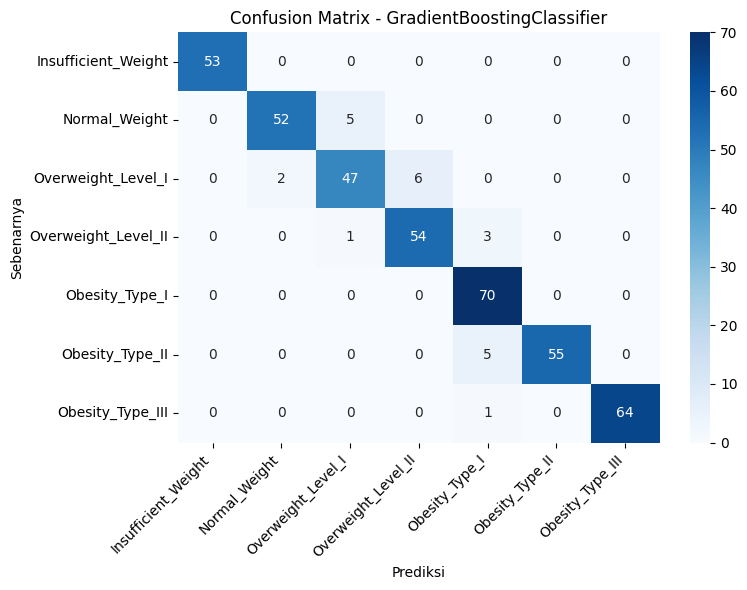

In [181]:
# Memilih model dengan F1-Score tertinggi
hasil_prediksi = {
    'KNN': pred_knn,
    'Logistic Regression': pred_LogR,
    'GradientBoostingClassifier': pred_GBC
}
model_terbaik = df_results['F1-Score'].idxmax()
print("Model terbaik:", model_terbaik)

# Confusion matrix untuk model terbaik
cm = confusion_matrix(y_test, hasil_prediksi[model_terbaik])
label = [k for k in kamus_target]

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label, yticklabels=label)
plt.title(f"Confusion Matrix - {model_terbaik}")
plt.xlabel("Prediksi")
plt.ylabel("Sebenarnya")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [182]:
# Laporan per kelas untuk model terbaik
print(classification_report(y_test, hasil_prediksi[model_terbaik], target_names=label, zero_division=0))

                     precision    recall  f1-score   support

Insufficient_Weight       1.00      1.00      1.00        53
      Normal_Weight       0.96      0.91      0.94        57
 Overweight_Level_I       0.89      0.85      0.87        55
Overweight_Level_II       0.90      0.93      0.92        58
     Obesity_Type_I       0.89      1.00      0.94        70
    Obesity_Type_II       1.00      0.92      0.96        60
   Obesity_Type_III       1.00      0.98      0.99        65

           accuracy                           0.94       418
          macro avg       0.95      0.94      0.94       418
       weighted avg       0.95      0.94      0.95       418



In [183]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBC, 'gbc_model.joblib')
joblib.dump(scaler, 'scaler.joblib')

['scaler.joblib']

In [184]:
import pickle

# Menyimpan model ke dalam file
with open('gbc_model.pkl', 'wb') as file:
    pickle.dump(GBC, file)

In [185]:
import joblib
import pickle
from sklearn.metrics import accuracy_score

# Memuat model dari file joblib
joblib_model = joblib.load('gbc_model.joblib')

# Memuat model dari file pickle
with open('gbc_model.pkl', 'rb') as file:
    pickle_model = pickle.load(file)

pred_asli   = GBC.predict(X_test_s)
pred_joblib = joblib_model.predict(X_test_s)
pred_pickle = pickle_model.predict(X_test_s)

print("Accuracy model asli :", accuracy_score(y_test, pred_asli))
print("Accuracy joblib     :", accuracy_score(y_test, pred_joblib))
print("Accuracy pickle     :", accuracy_score(y_test, pred_pickle))
print("Prediksi sama semua?:", (pred_asli == pred_joblib).all() and (pred_asli == pred_pickle).all())

Accuracy model asli : 0.9449760765550239
Accuracy joblib     : 0.9449760765550239
Accuracy pickle     : 0.9449760765550239
Prediksi sama semua?: True


In [ ]:
import joblib

joblib.dump(list(X_enc.columns), 'kolom_fitur.joblib')
print(list(X_enc.columns))

In [186]:
import joblib
import pandas as pd
from flask import Flask, request, jsonify

app = Flask(__name__)

# Memuat model, scaler, dan daftar kolom fitur
model = joblib.load('gbc_model.joblib')
scaler = joblib.load('scaler.joblib')
kolom_fitur = joblib.load('kolom_fitur.joblib')

# Kamus encoding (sama seperti di notebook)
biner = {'no': 0, 'yes': 1}
tingkat = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
label_target = {
    0: 'Insufficient_Weight', 1: 'Normal_Weight',
    2: 'Overweight_Level_I', 3: 'Overweight_Level_II',
    4: 'Obesity_Type_I', 5: 'Obesity_Type_II', 6: 'Obesity_Type_III'
}
kolom_scale = ['Age', 'Height', 'Weight']


def proses_data(data):
    """Mengubah data mentah dari pengguna menjadi bentuk yang siap diprediksi."""
    df = pd.DataFrame([data])

    # Encoding
    df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
    for k in ['FAVC', 'SCC', 'SMOKE', 'family_history_with_overweight']:
        df[k] = df[k].map(biner)
    for k in ['CALC', 'CAEC']:
        df[k] = df[k].map(tingkat)
    df = pd.get_dummies(df, columns=['MTRANS'])

    # Samakan kolom dengan data latih (kolom yang tidak ada diisi 0)
    df = df.reindex(columns=kolom_fitur, fill_value=0).astype(float)

    # Standardisasi Age, Height, Weight memakai scaler dari data latih
    df[kolom_scale] = scaler.transform(df[kolom_scale])
    return df


@app.route('/')
def home():
    return jsonify({'pesan': 'API prediksi tingkat obesitas berjalan'})


@app.route('/predict', methods=['POST'])
def predict():
    try:
        data = request.get_json()
        X = proses_data(data)
        kode = int(model.predict(X)[0])
        return jsonify({'kode': kode, 'prediksi': label_target[kode]})
    except Exception as e:
        return jsonify({'error': str(e)}), 400


if __name__ == '__main__':
    app.run(debug=True)

FileNotFoundError: [Errno 2] No such file or directory: 'kolom_fitur.joblib'